# Entrega 2 (mejora) · ¿Generaliza la BiGRU a errores que no vio?
**Observación del profesor:** *las pruebas en los datos sintéticos pueden ser optimistas porque entrenamiento, validación y prueba siguen las mismas reglas de cambio; podrían crear cada conjunto con reglas diferentes. La otra limitación es que el conjunto real es muy pequeño y la ganancia de estas arquitecturas frente a la distancia es poca.*

**Qué se hace.**
1. **Reglas distintas por partición (*leave-one-family-out*).** El generador de la entrega tiene 5 familias de error (`edit`, `espacio`, `codif`, `abrev`, `tokens`). En cada ronda se entrena y valida con 4 familias y se prueba con la quinta, que la red nunca vio. Se compara con la prueba de la misma regla (la optimista de la entrega) y con la distancia de edición.
2. **Tamaño de la prueba real.** Intervalos de confianza de Wilson para la exactitud real y prueba de McNemar para comparar la red con la distancia de edición en los mismos textos.
3. **Cascada.** Si la red no supera claramente a la distancia, ¿sirve como segunda opinión cuando la distancia tiene baja similitud?

El código del generador, las arquitecturas y el entrenamiento es **el mismo de la entrega 2** (se copia del notebook original); solo cambia el diseño de las particiones.

In [1]:
import os, re, json, unicodedata, random, warnings, time, sys, itertools, collections
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf, keras
from keras import layers
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
try:
    from rapidfuzz import process, fuzz
except ImportError:                                   # rapidfuzz solo acelera la línea base
    import subprocess; subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rapidfuzz"]); from rapidfuzz import process, fuzz
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

PAR = dict(SEMILLA_PRUEBA=1000, UMBRAL_CASCADA=0.80, SEMILLA=42, SEMILLAS_EXTRA=[1, 2], VARIANTES_POR_CLASE=80, FRAC_VAL=0.15, FRAC_TEST=0.15, MAXLEN=40,
           EMB=64, GRU=96, D_MODELO=64, CABEZAS=4, FF=128, BLOQUES=2, DROPOUT=0.3, LR=1e-3, BATCH=128, EPOCAS=60, PACIENCIA=6, UMBRAL_CONF=0.50)
RES = {"parametros": PAR, "versiones": {"python": sys.version.split()[0], "tensorflow": tf.__version__, "keras": keras.__version__, "numpy": np.__version__, "pandas": pd.__version__}}
def fijar_semilla(s): random.seed(s); np.random.seed(s); keras.utils.set_random_seed(s)
fijar_semilla(PAR["SEMILLA"])
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
from scipy.stats import binomtest
from statsmodels.stats.proportion import proportion_confint

I0000 00:00:1792849400.812207     438 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792849400.812740     438 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792849402.041825     438 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792849402.042170     438 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow 2.21.0 | Keras 3.15.1


In [2]:
def nrm(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().upper()
    return re.sub(r"\s+", " ", re.sub(r"[^A-Z0-9 ]", " ", s)).strip()

dpa = pd.read_csv("datos/dpa_cantones.csv", dtype=str)
terr = pd.read_parquet("datos/territory.parquet"); terr = terr[terr.rol == "cantón"].copy(); terr["vn"] = terr.valor.map(nrm)
dic = pd.read_csv("datos/diccionario_correccion_canton.csv", encoding="utf-8-sig"); dic["x"] = dic.valor.map(nrm); dic["y"] = dic.canton_oficial_sugerido.map(nrm)

CLASES = sorted(set(dpa.canton_norm)); C2I = {c: i for i, c in enumerate(CLASES)}; NC = len(CLASES)
# alias oficiales: nombre de la cabecera cantonal cuando difiere del nombre del cantón (misma regla que el EDA)
alias = {}
for cab, k in zip(dpa.cabecera_norm, dpa.canton_norm):
    if isinstance(cab, str) and cab not in C2I: alias[cab] = k
for cab, k in list(alias.items()):
    b = nrm(re.sub(r"\(.*\)|CABECERA CANTONAL", "", cab))
    if b and b not in C2I: alias.setdefault(b, k)
alias = {nrm(a): k for a, k in alias.items() if nrm(a) not in C2I}
fuentes = [(c, c) for c in CLASES] + [(a, k) for a, k in alias.items()]      # (texto base, clase)

# prueba real: cadenas distintas normalizadas del diccionario manual (se suman sus registros)
real = dic.groupby(["x", "y"], as_index=False).agg(registros=("registros", "sum"), variantes_crudas=("valor", "nunique"))
assert real.x.is_unique and set(real.y) <= set(CLASES)
n_reg_canton = int(terr.n.sum())
RES["datos"] = dict(cantones_oficiales=len(dpa), clases=NC, alias_cabecera=len(alias), textos_crudos_distintos=int(terr.valor.nunique()),
                    textos_normalizados_distintos=int(terr.vn.nunique()), registros_con_canton=n_reg_canton,
                    dic_filas=len(dic), dic_cadenas_distintas=len(real), dic_registros=int(dic.registros.sum()),
                    dic_pct_registros=round(float(dic.registros.sum() / n_reg_canton * 100), 2))
print(RES["datos"]); print(real.sort_values("registros", ascending=False).head(8))

{'cantones_oficiales': 221, 'clases': 219, 'alias_cabecera': 58, 'textos_crudos_distintos': 1078, 'textos_normalizados_distintos': 701, 'registros_con_canton': 6336984, 'dic_filas': 50, 'dic_cadenas_distintas': 38, 'dic_registros': 19104, 'dic_pct_registros': 0.3}
                               x                            y  registros  \
27  PUERTO FRANCISCO DE ORELLANA        FRANCISCO DE ORELLANA       5250   
28                     RIO VERDE                     RIOVERDE       2979   
24                  PUEBLO VIEJO                  PUEBLOVIEJO       2780   
13        GNRAL ANTONIO ELIZALDE     GENERAL ANTONIO ELIZALDE       2543   
10      CRNEL MARCELINO MARIDUEA  CORONEL MARCELINO MARIDUENA       1867   
15            JOYA DE LOS SACHAS        LA JOYA DE LOS SACHAS        827   
6           CAMILO PONCE ENRIQUE        CAMILO PONCE ENRIQUEZ        739   
12     CRNEL MARCELINO MARIDUENA  CORONEL MARCELINO MARIDUENA        719   

    variantes_crudas  
27                 2  
28  

In [3]:
STOP = ["DE", "LA", "LAS", "LOS", "EL", "DEL"]
PREFIJOS = ["CANTON", "CIUDAD", "CABECERA CANTONAL", "MUNICIPIO DE", "GAD"]
LETRAS = list("ABCDEFGHIJKLMNOPQRSTUVWXYZ")
VECINAS = {"Q": "WA", "W": "QES", "E": "WRD", "R": "ETF", "T": "RYG", "Y": "TUH", "U": "YIJ", "I": "UOK", "O": "IPL", "P": "O", "A": "QSZ", "S": "ADW", "D": "SFE", "F": "DGR", "G": "FHT",
           "H": "GJY", "J": "HKU", "K": "JLI", "L": "KO", "Z": "AX", "X": "ZC", "C": "XV", "V": "CB", "B": "VN", "N": "BM", "M": "N"}

def op_edit(s, rng):
    for _ in range(int(rng.choice([1, 2, 3], p=[0.55, 0.35, 0.10]))):
        if len(s) < 3: break
        i = int(rng.integers(len(s))); t = rng.choice(["del", "ins", "sub", "swap"])
        if t == "del": s = s[:i] + s[i + 1:]
        elif t == "ins": s = s[:i] + str(rng.choice(LETRAS)) + s[i:]
        elif t == "sub" and s[i] != " ": s = s[:i] + str(rng.choice(list(VECINAS.get(s[i], "AEIOU")) + LETRAS)) + s[i + 1:]
        elif t == "swap" and i + 1 < len(s): s = s[:i] + s[i + 1] + s[i] + s[i + 2:]
    return s
def op_espacio(s, rng):
    t = rng.choice(["quitar", "quitar_todos", "agregar"])
    esp = [i for i, ch in enumerate(s) if ch == " "]
    if t == "quitar" and esp: i = int(rng.choice(esp)); return s[:i] + s[i + 1:]
    if t == "quitar_todos": return s.replace(" ", "")
    if t == "agregar" and len(s) > 4:
        i = int(rng.integers(2, len(s) - 1)); return s if " " in (s[i - 1], s[i]) else s[:i] + " " + s[i:]
    return s
def op_codif(s, rng):
    pos = [i for i, ch in enumerate(s) if ch in "NAEIOU"]
    if not pos: return s
    i = int(rng.choice([p for p in pos if s[p] == "N"] or pos)); r = rng.choice(["perder", "A", "espacio", "AA"])
    return s[:i] + {"perder": "", "A": "A", "espacio": " ", "AA": "AA"}[str(r)] + s[i + 1:]
def op_abrev(s, rng):
    pal = s.split(); largas = [i for i, p in enumerate(pal) if len(p) >= 5]
    if not largas: return s
    i = int(rng.choice(largas)); p = pal[i]; t = rng.choice(["vocales", "truncar", "inicial"])
    if t == "vocales": p = p[0] + "".join(ch for ch in p[1:-1] if ch not in "AEIOU" or rng.random() < 0.3) + p[-1]
    elif t == "truncar": p = p[:int(rng.integers(3, max(4, len(p) - 1)))]
    else: p = p[0]
    pal[i] = p; return " ".join(pal)
def op_tokens(s, rng):
    pal = s.split(); t = rng.choice(["quitar", "prefijo"])
    cand = [i for i, p in enumerate(pal) if p in STOP]
    if t == "quitar" and cand: pal.pop(int(rng.choice(cand))); return " ".join(pal)
    return str(rng.choice(PREFIJOS)) + " " + s
FAMILIAS = {"edit": op_edit, "espacio": op_espacio, "codif": op_codif, "abrev": op_abrev, "tokens": op_tokens}
TODAS, BASICAS = ["edit", "espacio", "codif", "abrev", "tokens"], ["edit", "espacio"]
PESOS = {"edit": 0.40, "espacio": 0.15, "codif": 0.20, "abrev": 0.15, "tokens": 0.10}

from rapidfuzz.distance import Levenshtein
def variante(base, rng, fams):
    """Aplica 1-2 operaciones de ruido; exige que el resultado siga siendo reconocible (distancia ≤ 30 % del nombre) salvo prefijos institucionales."""
    p = np.array([PESOS[f] for f in fams]); p = p / p.sum()
    for _ in range(8):
        v, usa_prefijo = base, False
        for _ in range(int(rng.choice([1, 2], p=[0.75, 0.25]))):
            f = str(rng.choice(fams, p=p)); v = FAMILIAS[f](v, rng); usa_prefijo |= (f == "tokens")
        v = nrm(v); core = v
        for pf in PREFIJOS: core = core[len(pf) + 1:] if core.startswith(pf + " ") else core
        if Levenshtein.distance(core, nrm(base)) <= max(1, int(0.3 * len(base))): return v
    return nrm(base)

def generar_corpus(fams, semilla, n_por_clase=PAR["VARIANTES_POR_CLASE"]):
    rng = np.random.default_rng(semilla); vistos = {}
    prohibidas = set(real.x)                                   # nada de la prueba real entra al corpus
    for base, clase in fuentes:
        vistos.setdefault(base, set()).add(clase)
        for _ in range(n_por_clase if base == clase else n_por_clase // 2):
            v = variante(base, rng, fams)
            if len(v) >= 2 and v not in prohibidas: vistos.setdefault(v, set()).add(clase)
    filas = [(t, next(iter(c))) for t, c in vistos.items() if len(c) == 1]          # se descartan cadenas ambiguas
    df = pd.DataFrame(filas, columns=["texto", "clase"]).drop_duplicates("texto")
    df["y"] = df.clase.map(C2I); return df

corpus = generar_corpus(TODAS, PAR["SEMILLA"])  # corpus original de la entrega (referencia)
print("Textos distintos del corpus:", len(corpus), "| clases:", corpus.clase.nunique(), "| mediana por clase:", int(corpus.groupby("clase").size().median()))
print(corpus.sample(10, random_state=1)[["texto", "clase"]].rename(columns={"texto": "texto con ruido"}))

Textos distintos del corpus: 11721 | clases: 219 | mediana por clase: 52
        texto con ruido          clase
1989           COTZACHI      COTACACHI
7714   SARNH MCRISTOBAL  SAN CRISTOBAL
2897       BLAVIO LFARO  FLAVIO ALFARO
2293      GAD ECHEANDIA      ECHEANDIA
8465         SANTAELENA    SANTA ELENA
3589          HUUAMBOYA       HUAMBOYA
2574         EL PANGUVI      EL PANGUI
4152             LA MNA        LA MANA
135              ALTUSI         ALAUSI
11363  XPUERTO KILLAIML        ISABELA


In [4]:
# División estratificada por clase sobre textos únicos: ningún texto idéntico aparece en dos particiones.
def dividir(df, semilla):
    tr, rest = train_test_split(df, test_size=PAR["FRAC_VAL"] + PAR["FRAC_TEST"], stratify=df.y, random_state=semilla)
    va, te = train_test_split(rest, test_size=PAR["FRAC_TEST"] / (PAR["FRAC_VAL"] + PAR["FRAC_TEST"]), stratify=rest.y, random_state=semilla)
    return tr.reset_index(drop=True), va.reset_index(drop=True), te.reset_index(drop=True)


In [5]:
# Tras `nrm` el alfabeto es cerrado: espacio, A-Z y 0-9 (los demás símbolos ya se convirtieron en espacio). 0 = relleno, 1 = desconocido (no ocurre).
ALFABETO = " ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789"
vocab = ["<PAD>", "<UNK>"] + list(ALFABETO); CH2I = {c: i for i, c in enumerate(vocab)}; V = len(vocab)
def codificar(textos, maxlen=PAR["MAXLEN"]):
    X = np.zeros((len(textos), maxlen), dtype="int32")
    for i, t in enumerate(textos):
        ids = [CH2I.get(ch, 1) for ch in t][:maxlen]; X[i, :len(ids)] = ids
    return X
Xre, yre = codificar(real.x), real.y.map(C2I).values

In [6]:
from rapidfuzz import process
from rapidfuzz.distance import Levenshtein
cand_txt = [b for b, _ in fuentes]; cand_cls = np.array([C2I[c] for _, c in fuentes])
def base_edicion(textos):
    return np.array([cand_cls[process.extractOne(t, cand_txt, scorer=Levenshtein.normalized_similarity)[2]] for t in textos])

def metr_sint(y, yp):
    p, r, f, _ = precision_recall_fscore_support(y, yp, labels=range(NC), average="macro", zero_division=0)
    return dict(acc=float(accuracy_score(y, yp)), precision=float(p), recall=float(r), f1=float(f))
def metr_real(yp):
    ok = (yp == yre); w = real.registros.values
    return dict(acc=float(ok.mean()), aciertos=int(ok.sum()), n=int(len(ok)), acc_ponderada=float((ok * w).sum() / w.sum()))

yp_b_re = base_edicion(real.x)

In [7]:
class CodificacionPosicional(layers.Layer):
    """Embedding de caracteres + codificación posicional sinusoidal (Vaswani et al., 2017)."""
    def __init__(self, vocab, d, maxlen, **kw):
        super().__init__(**kw); self.d, self.maxlen = d, maxlen; self.emb = layers.Embedding(vocab, d)
        pos = np.arange(maxlen)[:, None]; i = np.arange(d)[None, :]; ang = pos / np.power(10000.0, (2 * (i // 2)) / d)
        pe = np.where(i % 2 == 0, np.sin(ang), np.cos(ang)).astype("float32"); self.pe = tf.constant(pe[None])
    def call(self, x): return self.emb(x) * float(np.sqrt(self.d)) + self.pe[:, :tf.shape(x)[1]]

class BloqueTransformer(layers.Layer):
    def __init__(self, d, cabezas, ff, drop, **kw):
        super().__init__(**kw); self.att = layers.MultiHeadAttention(num_heads=cabezas, key_dim=d // cabezas)
        self.ffn = keras.Sequential([layers.Dense(ff, activation="relu"), layers.Dense(d)])
        self.n1, self.n2 = layers.LayerNormalization(epsilon=1e-6), layers.LayerNormalization(epsilon=1e-6); self.d1, self.d2 = layers.Dropout(drop), layers.Dropout(drop)
    def call(self, x, ids, training=False):
        mask = tf.not_equal(ids, 0); am = tf.logical_and(mask[:, :, None], mask[:, None, :])                 # (B,T,T): ningún carácter atiende al relleno
        x = self.n1(x + self.d1(self.att(x, x, attention_mask=am), training=training))
        return self.n2(x + self.d2(self.ffn(x), training=training))

class PromedioEnmascarado(layers.Layer):
    def call(self, x, ids):
        m = tf.cast(tf.not_equal(ids, 0), x.dtype)[:, :, None]; return tf.reduce_sum(x * m, 1) / tf.maximum(tf.reduce_sum(m, 1), 1.0)

def construir(nombre):
    entrada = keras.Input((PAR["MAXLEN"],), dtype="int32")
    if nombre == "BiGRU":
        x = layers.Embedding(V, PAR["EMB"], mask_zero=True)(entrada)
        x = layers.Bidirectional(layers.GRU(PAR["GRU"], return_sequences=True))(x)
        x = layers.Bidirectional(layers.GRU(PAR["GRU"]))(x)
    else:
        x = CodificacionPosicional(V, PAR["D_MODELO"], PAR["MAXLEN"])(entrada)
        for _ in range(PAR["BLOQUES"]): x = BloqueTransformer(PAR["D_MODELO"], PAR["CABEZAS"], PAR["FF"], 0.1)(x, entrada)
        x = PromedioEnmascarado()(x, entrada)
    x = layers.Dropout(PAR["DROPOUT"])(x); x = layers.Dense(256, activation="relu")(x); x = layers.Dropout(PAR["DROPOUT"])(x)
    return keras.Model(entrada, layers.Dense(NC, activation="softmax")(x), name=nombre)



In [8]:
def entrenar(nombre, semilla, datos=None, verbose=0):
    datos = datos or D; fijar_semilla(semilla); m = construir(nombre)
    m.compile(optimizer=keras.optimizers.Adam(PAR["LR"]), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=PAR["PACIENCIA"], restore_best_weights=True),
          keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)]
    t0 = time.time(); h = m.fit(datos["Xtr"], datos["ytr"], validation_data=(datos["Xva"], datos["yva"]), epochs=PAR["EPOCAS"], batch_size=PAR["BATCH"], callbacks=cb, verbose=verbose)
    return m, h.history, time.time() - t0

def evaluar_modelo(m, datos=None):
    datos = datos or D; p_te = m.predict(datos["Xte"], verbose=0); p_re = m.predict(Xre, verbose=0)
    return dict(sintetico=metr_sint(datos["yte"], p_te.argmax(1)), real=metr_real(p_re.argmax(1))), p_te, p_re



## 1. Prueba con reglas distintas a las del entrenamiento
Para cada familia *f*: corpus de entrenamiento y validación con las otras 4 (misma semilla y tamaño que la entrega), división 70/15/15 como en la entrega (el 15 % de prueba es la **prueba de misma regla**) y una **prueba de regla nueva** generada solo con *f* y otra semilla, sin textos que aparezcan en el corpus de entrenamiento ni nombres limpios.

In [9]:
def similitud_max(textos):
    return np.array([process.extractOne(t, cand_txt, scorer=Levenshtein.normalized_similarity)[1] for t in textos])

FILAS, PRED = [], {}
for k, fam in enumerate(TODAS):
    otras = [f for f in TODAS if f != fam]
    corp = generar_corpus(otras, PAR["SEMILLA"]); tr, va, te = dividir(corp, PAR["SEMILLA"])
    nuevo = generar_corpus([fam], PAR["SEMILLA_PRUEBA"] + k)
    nuevo = nuevo[~nuevo.texto.isin(set(corp.texto)) & ~nuevo.texto.isin(set(CLASES) | set(alias))].reset_index(drop=True)
    datos = dict(Xtr=codificar(tr.texto), ytr=tr.y.values, Xva=codificar(va.texto), yva=va.y.values, Xte=codificar(te.texto), yte=te.y.values)
    m, hist, seg = entrenar("BiGRU", PAR["SEMILLA"], datos)
    for nombre_prueba, df in (("misma regla", te), ("regla nueva", nuevo)):
        yp_red = m.predict(codificar(df.texto), verbose=0).argmax(1); yp_dist = base_edicion(df.texto.tolist()); y = df.y.values
        sim = similitud_max(df.texto.tolist()); yp_cas = np.where(sim >= PAR["UMBRAL_CASCADA"], yp_dist, yp_red)
        for metodo, yp in (("BiGRU", yp_red), ("Distancia de edición", yp_dist), ("Cascada", yp_cas)):
            FILAS.append(dict(familia_probada=fam, prueba=nombre_prueba, metodo=metodo, n=len(y), **metr_sint(y, yp)))
        PRED[(fam, nombre_prueba)] = dict(y=y, red=yp_red, dist=yp_dist, cas=yp_cas)
    print(f"{fam:8s} | entrenado con {otras} | {len(tr)} textos, {len(hist['loss'])} épocas, {seg:.0f} s | prueba regla nueva: {len(nuevo)} textos")
R = pd.DataFrame(FILAS)
tabla = R.pivot_table(index=["familia_probada", "prueba"], columns="metodo", values="acc").round(3)
tabla

edit     | entrenado con ['espacio', 'codif', 'abrev', 'tokens'] | 4908 textos, 47 épocas, 416 s | prueba regla nueva: 14715 textos


espacio  | entrenado con ['edit', 'codif', 'abrev', 'tokens'] | 8685 textos, 48 épocas, 482 s | prueba regla nueva: 1990 textos


codif    | entrenado con ['edit', 'espacio', 'abrev', 'tokens'] | 8581 textos, 37 épocas, 375 s | prueba regla nueva: 3714 textos


abrev    | entrenado con ['edit', 'espacio', 'codif', 'tokens'] | 8335 textos, 41 épocas, 412 s | prueba regla nueva: 1666 textos


tokens   | entrenado con ['edit', 'espacio', 'codif', 'abrev'] | 7933 textos, 58 épocas, 566 s | prueba regla nueva: 2949 textos


metodo                       BiGRU  Cascada  Distancia de edición
familia_probada prueba                                           
abrev           misma regla  0.976    0.986                 0.939
                regla nueva  0.887    0.918                 0.995
codif           misma regla  0.965    0.977                 0.931
                regla nueva  0.913    0.939                 0.998
edit            misma regla  0.981    0.984                 0.873
                regla nueva  0.801    0.929                 0.997
espacio         misma regla  0.976    0.989                 0.937
                regla nueva  1.000    1.000                 1.000
tokens          misma regla  0.976    0.990                 0.998
                regla nueva  0.255    0.258                 0.485

In [10]:
# Resumen: media sobre las 5 familias; y prueba de McNemar (exacta) red vs distancia en la prueba de regla nueva
res = R.groupby(["prueba", "metodo"])[["acc", "f1"]].mean().round(3)
mc = []
for fam in TODAS:
    p = PRED[(fam, "regla nueva")]; a = p["red"] == p["y"]; b = p["dist"] == p["y"]
    n01, n10 = int((~a & b).sum()), int((a & ~b).sum())     # solo acierta la distancia / solo acierta la red
    pv = binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
    mc.append(dict(familia=fam, solo_red=n10, solo_distancia=n01, p_valor=round(float(pv), 4)))
MC = pd.DataFrame(mc); print(res); MC

                                    acc     f1
prueba      metodo                            
misma regla BiGRU                 0.975  0.972
            Cascada               0.985  0.984
            Distancia de edición  0.935  0.933
regla nueva BiGRU                 0.771  0.706
            Cascada               0.809  0.748
            Distancia de edición  0.895  0.855


,familia,solo_red,solo_distancia,p_valor
0,edit,24,2906,0.0
1,espacio,0,0,1.0
2,codif,1,318,0.0
3,abrev,4,183,0.0
4,tokens,125,803,0.0


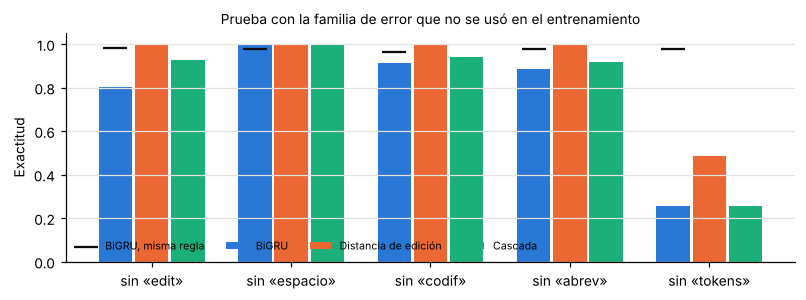

In [11]:
fig, ax = plt.subplots(figsize=(7.4, 2.8)); w = 0.26; x = np.arange(len(TODAS))
for j, (met, col) in enumerate((("BiGRU", "#2a78d6"), ("Distancia de edición", "#eb6834"), ("Cascada", "#1baf7a"))):
    v = [tabla.loc[(f, "regla nueva"), met] for f in TODAS]
    ax.bar(x + (j - 1) * w, v, w * 0.92, color=col, label=met)
    if met == "BiGRU":
        ax.scatter(x - w, [tabla.loc[(f, "misma regla"), met] for f in TODAS], marker="_", s=260, color="#0b0b0b", zorder=3, label="BiGRU, misma regla")
ax.set_xticks(x, [f"sin «{f}»" for f in TODAS]); ax.set_ylabel("Exactitud"); ax.set_ylim(0, 1.05); ax.grid(axis="y", color="#e4e3df")
ax.legend(frameon=False, fontsize=7, ncol=4, loc="lower left"); ax.set_title("Prueba con la familia de error que no se usó en el entrenamiento", fontsize=9)
plt.tight_layout(); plt.savefig("fig_w2_reglas_distintas.png", dpi=200); plt.show()

## 2. ¿Cuánto dice la prueba real de 38 cadenas?
Intervalo de confianza de Wilson al 95 % para la exactitud de cada método, y McNemar para la diferencia BiGRU frente a la distancia en las mismas 38 cadenas (resultados de la entrega 2).

In [12]:
w2 = json.load(open("resultados_W2.json"))
ic = []
for met, r in (("Distancia de edición", w2["baseline"]["real"]), ("BiGRU", w2["principal"]["BiGRU"]["real"]), ("Transformer", w2["principal"]["Transformer"]["real"])):
    lo, hi = proportion_confint(r["aciertos"], r["n"], method="wilson"); ic.append(dict(metodo=met, aciertos=f"{r['aciertos']}/{r['n']}", ic95_inf=round(lo, 3), ic95_sup=round(hi, 3)))
IC = pd.DataFrame(ic)
# n necesario para detectar una diferencia de 3 puntos (0,97 vs 0,94) con potencia 0,8 y alfa 0,05 (aprox. de proporciones independientes)
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
n_nec = int(np.ceil(NormalIndPower().solve_power(proportion_effectsize(0.97, 0.94), power=0.8, alpha=0.05)))
print("cadenas reales necesarias por método para distinguir 0,97 de 0,94:", n_nec); IC

cadenas reales necesarias por método para distinguir 0,97 de 0,94: 729


,metodo,aciertos,ic95_inf,ic95_sup
0,Distancia de edición,38/38,0.908,1.000
1,BiGRU,38/38,0.908,1.000
2,Transformer,36/38,0.827,0.985


In [13]:
RES = dict(reglas_distintas=R.to_dict("records"), resumen={f"{p} | {m}": dict(acc=float(v["acc"]), f1=float(v["f1"])) for (p, m), v in res.iterrows()},
           mcnemar=MC.to_dict("records"), real_ic=IC.to_dict("records"), n_necesario=n_nec, umbral_cascada=PAR["UMBRAL_CASCADA"])
json.dump(RES, open("resultados_W2_mejoras.json", "w"), ensure_ascii=False, indent=1, default=float); print("ok")

ok
